# 02 · Manifold — principal-curve trajectory (SmartSeq2 malignant manifold)

Jerby-Arnon 2021's synovial-sarcoma malignant manifold is **non-branching**: the developmental
signatures collapse onto a **single dominant axis** rather than a hub radiating into two
cross-repressing arms. A PPT **tree** placed on this compact cloud (aspect ~1.6) produces many
spurious forks that merely wallpaper a 2-D blob — the "tree-on-a-strip" over-fit the protocol warns
against — so a principal **curve** is the correct model. We score the three embryonic modules
against the shared **union** control pool, graph-smooth them for geography, confirm the
non-branching topology by an explicit tree-vs-curve test, fit a fold-free curve, and root it at the
Gast/pSom-high developmental origin.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Cells stay on their original joint embedding — **no re-embedding**. The three embryonic signatures
(Gastrulation / Somitogenesis / Neural-crest) are scored against the shared **union** control pool
and graph-smoothed (kNN-connectivity averaging) so geography is read from neighbourhood structure
rather than SmartSeq2 per-cell noise. Raw scores are retained for the deliverable UMAPs in 03.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c0 = xy - xy.mean(0); _,s,_ = np.linalg.svd(c0, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('module means (raw): Gast %.3f  pSom %.3f  Crest %.3f'
      % (adata.obs.Gast.mean(), adata.obs.pSom.mean(), adata.obs.Crest.mean()))

malignant manifold: 4338 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.64
Gast: 78/81 genes present
pSom: 95/98 genes present
Crest: 102/104 genes present
module means (raw): Gast -0.089  pSom 0.322  Crest 0.038


### Topology test — tree vs curve (biology + geometry)
Two independent reads settle the topology. **Geometry:** fit a PPT tree across a Nodes/lambda grid
and count branch nodes — a genuine bifurcation gives a stable low fork count with cells radiating
from a hub; here forks proliferate with node count (wallpapering a low-aspect blob). **Biology:**
the smoothed signatures form one axis — Gast and pSom **co-vary positively** and both oppose Crest
— not the Gast-vs-pSom mutual exclusivity that defines a branch. Both say non-branching -> fit a
curve.

In [4]:
import io, contextlib
print('smoothed spatial geography (Pearson r):')
for a_,b_ in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a_} vs {b_}: r = {np.corrcoef(adata.obs[a_], adata.obs[b_])[0,1]:+.2f}')
print('\nPPT tree fork count across a parameter grid (a bifurcation would be stable & low):')
for Nodes in [30, 50, 100]:
    b = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(b, method='ppt', Nodes=Nodes, ppt_lambda=5.0, ppt_sigma=0.65,
                    use_rep='X_umap', seed=SEED, plot=False)
    B = np.asarray(b.uns['graph']['B']); deg = (B>0).sum(0)
    print(f'  Nodes={Nodes:3d}: {int((deg==1).sum())} tips, {int((deg>=3).sum())} forks')
print('\n-> forks scale with node count over a compact cloud (over-fit), and Gast/pSom co-vary:')
print('   non-branching -> principal curve (Gate 3 = NA).')

smoothed spatial geography (Pearson r):
  Gast_sm vs pSom_sm: r = +0.23
  Crest_sm vs Gast_sm: r = -0.37
  Crest_sm vs pSom_sm: r = -0.35

PPT tree fork count across a parameter grid (a bifurcation would be stable & low):
  Nodes= 30: 8 tips, 6 forks
  Nodes= 50: 11 tips, 9 forks
  Nodes=100: 17 tips, 15 forks

-> forks scale with node count over a compact cloud (over-fit), and Gast/pSom co-vary:
   non-branching -> principal curve (Gate 3 = NA).


### House orientation — rigid rotation to horizontal (from 01)
The house orientation was derived once in 01 (axis of maximal variance -> horizontal, a
distance-preserving rigid rotation stored as `X_umap_lin`). Here we fix its sign so the progenitor
(low-pseudotime) pole sits on the left once the root is known, and re-use these exact coordinates in
03/04.

### Fit the principal curve (ElPiGraph) — fold-free check
`Nodes/epg_lambda/epg_mu` give a smooth monotone backbone. A **self-approach ratio** > 1 (minimum
distance between graph-non-adjacent nodes, in units of median edge length) certifies the curve does
not fold back on itself; `epg_mu=100` is strong bending regularisation keeping the arc smooth.

In [5]:
def fold_diag(adx):
    B = np.asarray(adx.uns['graph']['B']); F = adx.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a_ in range(F.shape[0]):
        for b_ in range(a_+1, F.shape[0]):
            if G[a_,b_] >= 3: dmin = min(dmin, np.sqrt(((F[a_]-F[b_])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks

import io, contextlib
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.95 (>1 = fold-free)


### Derive the root (data-driven) and pseudotime
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin.
Neural crest is developmentally **late**, so it belongs at the terminus, never the root. Pseudotime
then flows origin -> Crest terminus.

In [6]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
# orient house layout so progenitor (low t) is on the left
if np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1] < 0:
    adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]
print(f'corr(x_lin, pseudotime) = {np.corrcoef(adata.obsm["X_umap_lin"][:,0], t)[0,1]:+.2f} (progenitor on left)')
print('gradient along pseudotime (Spearman rho, smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  {s}: rho = {spearmanr(t, adata.obs[s])[0]:+.3f}')
cyc = pd.to_numeric(adata.obs.get('g2m_score'), errors='coerce').fillna(0).values
print(f'  g2m_score: rho = {spearmanr(t, cyc)[0]:+.3f} (cell cycle orthogonal to developmental axis)')

tip 0: Gast=-0.0750 pSom=+0.3080 Crest=+0.0089
tip 2: Gast=-0.1159 pSom=+0.3146 Crest=+0.0567
derived root = tip 0 (Gast/pSom-high, Crest-low)
corr(x_lin, pseudotime) = +0.97 (progenitor on left)
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho = -0.466
  pSom_sm: rho = -0.019
  Crest_sm: rho = +0.480
  g2m_score: rho = -0.006 (cell cycle orthogonal to developmental axis)


### Save manifold + trajectory figure (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime colour on the house orientation.

saved manifold.h5ad + manifold.pdf


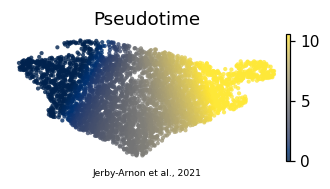

In [7]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Jerby-Arnon et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')